# Computational Optimization of a Wheat–Soy Biscuit Formulation

## Project Overview

This project develops a computational model inspired by biscuit preparation
experiments performed during high school.

Two formulations were previously prepared: a wheat-based formulation and a
wheat–soy formulation.

Because laboratory and food-processing equipment is not currently available,
this project focuses on the computational aspects of formulation analysis.

The original ingredient quantities are converted into normalized ratios,
allowing the formulations to be compared quantitatively.

The project then explores how changing the proportion of soy and wheat
affects the formulation while maintaining the total flour/soy base constant.

## Objectives

- Convert ingredient quantities into normalized formulation ratios
- Compare wheat-based and wheat–soy formulations
- Develop a computational formulation model
- Explore the effect of changing soy proportion
- Apply basic optimization concepts
- Visualize formulation changes
- Export the final formulation data

## Important Note

The computational formulations are models based on the quantities used in
the original preparation. They do not predict sensory properties, texture,
nutritional composition or product quality without experimental validation.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
wheat_recipe = {
    "Ingredient": [
        "Wheat flour",
        "Sugar",
        "Butter",
        "Yogurt/Milk",
        "Eggs",
        "Chocolate",
        "Vanilla sugar",
        "Baking powder",
        "Salt",
        "Lemon zest"
    ],

    "Quantity": [
        3000,
        1185,
        375,
        1185,
        12,
        75,
        120,
        5,
        2,
        5
    ],

    "Unit": [
        "g",
        "g",
        "g",
        "mL",
        "eggs",
        "g",
        "g",
        "g",
        "g",
        "g"
    ]
}

wheat_df = pd.DataFrame(wheat_recipe)

wheat_df

,Ingredient,Quantity,Unit
0,Wheat flour,3000,g
1,Sugar,1185,g
2,Butter,375,g
3,Yogurt/Milk,1185,mL
4,Eggs,12,eggs
5,Chocolate,75,g
6,Vanilla sugar,120,g
7,Baking powder,5,g
8,Salt,2,g
9,Lemon zest,5,g


In [ ]:
soy_recipe = {
    "Ingredient": [
        "Soy",
        "Wheat flour",
        "Sugar",
        "Milk",
        "Eggs",
        "Vanilla sugar",
        "Baking powder",
        "Margarine",
        "Chocolate"
    ],

    "Quantity": [
        879,
        1000,
        790,
        1000,
        6,
        80,
        10,
        180,
        100
    ],

    "Unit": [
        "g",
        "g",
        "g",
        "mL",
        "eggs",
        "g",
        "g",
        "g",
        "g"
    ]
}

soy_df = pd.DataFrame(soy_recipe)

soy_df

,Ingredient,Quantity,Unit
0,Soy,879,g
1,Wheat flour,1000,g
2,Sugar,790,g
3,Milk,1000,mL
4,Eggs,6,eggs
5,Vanilla sugar,80,g
6,Baking powder,10,g
7,Margarine,180,g
8,Chocolate,100,g


In [ ]:
soy_mass = 879
wheat_mass = 1000

total_base = soy_mass + wheat_mass

soy_percentage = (soy_mass / total_base) * 100
wheat_percentage = (wheat_mass / total_base) * 100

print("Soy percentage:", round(soy_percentage, 2), "%")
print("Wheat percentage:", round(wheat_percentage, 2), "%")

Soy percentage: 46.78 %
Wheat percentage: 53.22 %


In [ ]:
formulation = pd.DataFrame({
    "Ingredient": ["Soy", "Wheat"],
    "Mass_g": [soy_mass, wheat_mass],
    "Percentage": [soy_percentage, wheat_percentage]
})

formulation["Percentage"] = formulation["Percentage"].round(2)

formulation

,Ingredient,Mass_g,Percentage
0,Soy,879,46.78
1,Wheat,1000,53.22


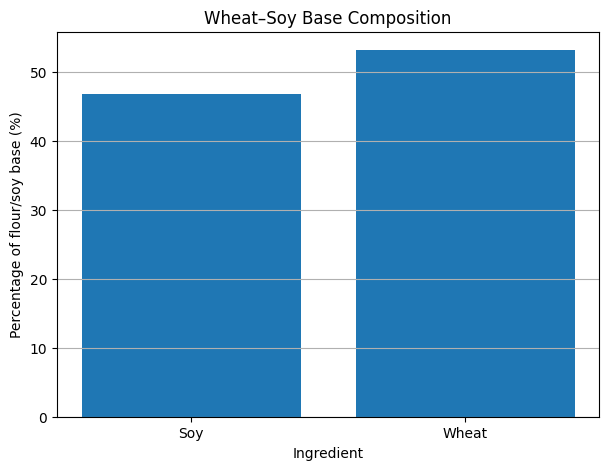

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    formulation["Ingredient"],
    formulation["Percentage"]
)

plt.xlabel("Ingredient")
plt.ylabel("Percentage of flour/soy base (%)")
plt.title("Wheat–Soy Base Composition")

plt.grid(axis="y")

plt.show()

In [ ]:
total_base_mass = 2000

soy_percentages = np.arange(0, 101, 10)

formulations = []

for soy_percent in soy_percentages:

    soy_mass = total_base_mass * soy_percent / 100
    wheat_mass = total_base_mass - soy_mass

    formulations.append([
        soy_percent,
        soy_mass,
        wheat_mass
    ])

formulation_df = pd.DataFrame(
    formulations,
    columns=[
        "Soy_percentage",
        "Soy_mass_g",
        "Wheat_mass_g"
    ]
)

formulation_df

,Soy_percentage,Soy_mass_g,Wheat_mass_g
0,0,0.0,2000.0
1,10,200.0,1800.0
2,20,400.0,1600.0
3,30,600.0,1400.0
4,40,800.0,1200.0
5,50,1000.0,1000.0
6,60,1200.0,800.0
7,70,1400.0,600.0
8,80,1600.0,400.0
9,90,1800.0,200.0


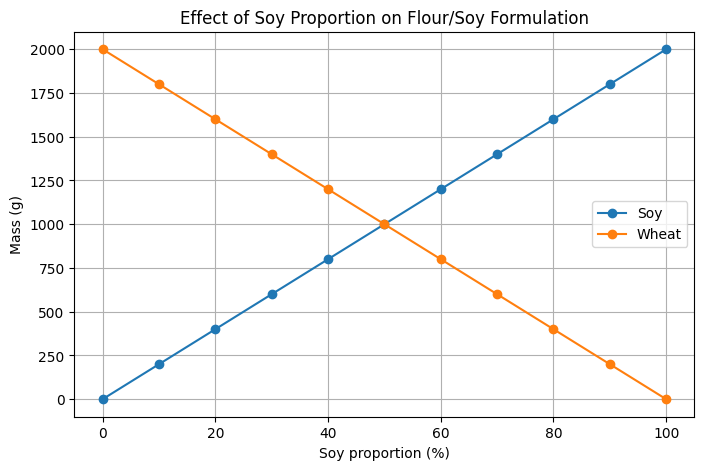

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    formulation_df["Soy_percentage"],
    formulation_df["Soy_mass_g"],
    marker="o",
    label="Soy"
)

plt.plot(
    formulation_df["Soy_percentage"],
    formulation_df["Wheat_mass_g"],
    marker="o",
    label="Wheat"
)

plt.xlabel("Soy proportion (%)")
plt.ylabel("Mass (g)")
plt.title("Effect of Soy Proportion on Flour/Soy Formulation")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
wheat_price = 1.00
soy_price = 2.00

formulation_df["Wheat_cost"] = (
    formulation_df["Wheat_mass_g"] / 1000
) * wheat_price

formulation_df["Soy_cost"] = (
    formulation_df["Soy_mass_g"] / 1000
) * soy_price

formulation_df["Total_base_cost"] = (
    formulation_df["Wheat_cost"]
    + formulation_df["Soy_cost"]
)

formulation_df

,Soy_percentage,Soy_mass_g,Wheat_mass_g,Wheat_cost,Soy_cost,Total_base_cost
0,0,0.0,2000.0,2.0,0.0,2.0
1,10,200.0,1800.0,1.8,0.4,2.2
2,20,400.0,1600.0,1.6,0.8,2.4
3,30,600.0,1400.0,1.4,1.2,2.6
4,40,800.0,1200.0,1.2,1.6,2.8
5,50,1000.0,1000.0,1.0,2.0,3.0
6,60,1200.0,800.0,0.8,2.4,3.2
7,70,1400.0,600.0,0.6,2.8,3.4
8,80,1600.0,400.0,0.4,3.2,3.6
9,90,1800.0,200.0,0.2,3.6,3.8


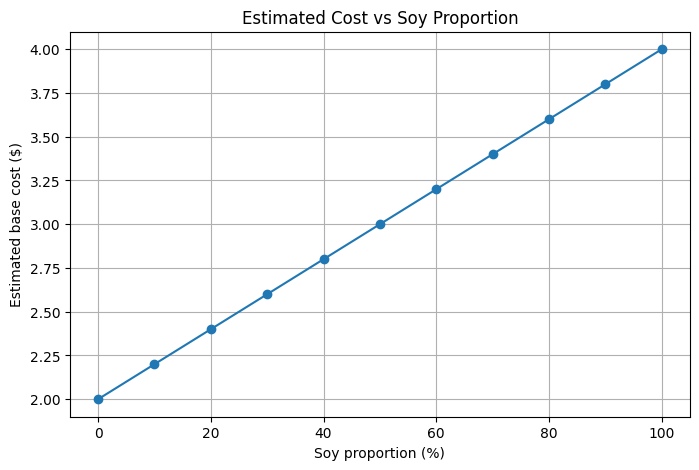

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    formulation_df["Soy_percentage"],
    formulation_df["Total_base_cost"],
    marker="o"
)

plt.xlabel("Soy proportion (%)")
plt.ylabel("Estimated base cost ($)")
plt.title("Estimated Cost vs Soy Proportion")

plt.grid(True)

plt.show()

In [ ]:
allowed_formulations = formulation_df[
    (formulation_df["Soy_percentage"] >= 30) &
    (formulation_df["Soy_percentage"] <= 60)
]

allowed_formulations

,Soy_percentage,Soy_mass_g,Wheat_mass_g,Wheat_cost,Soy_cost,Total_base_cost
3,30,600.0,1400.0,1.4,1.2,2.6
4,40,800.0,1200.0,1.2,1.6,2.8
5,50,1000.0,1000.0,1.0,2.0,3.0
6,60,1200.0,800.0,0.8,2.4,3.2


In [ ]:
best_formulation = allowed_formulations.loc[
    allowed_formulations["Total_base_cost"].idxmin()
]

print("Recommended formulation:")
print(best_formulation)

Recommended formulation:
Soy_percentage       30.0
Soy_mass_g          600.0
Wheat_mass_g       1400.0
Wheat_cost            1.4
Soy_cost              1.2
Total_base_cost       2.6
Name: 3, dtype: float64


In [ ]:
optimized_formulations = formulation_df[
    (formulation_df["Soy_percentage"] >= 40) &
    (formulation_df["Soy_percentage"] <= 60)
]

optimized_formulations

,Soy_percentage,Soy_mass_g,Wheat_mass_g,Wheat_cost,Soy_cost,Total_base_cost
4,40,800.0,1200.0,1.2,1.6,2.8
5,50,1000.0,1000.0,1.0,2.0,3.0
6,60,1200.0,800.0,0.8,2.4,3.2


In [ ]:
best_formulation = optimized_formulations.loc[
    optimized_formulations["Total_base_cost"].idxmin()
]

print("Lowest-cost formulation within the 40–60% soy range:")
print(best_formulation)

Lowest-cost formulation within the 40–60% soy range:
Soy_percentage       40.0
Soy_mass_g          800.0
Wheat_mass_g       1200.0
Wheat_cost            1.2
Soy_cost              1.6
Total_base_cost       2.8
Name: 4, dtype: float64


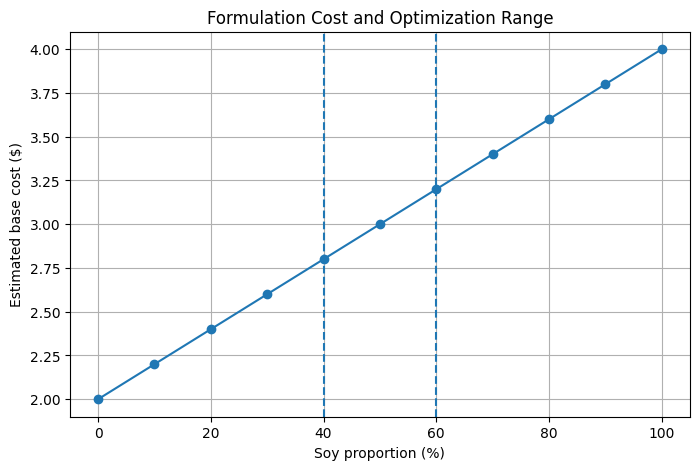

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    formulation_df["Soy_percentage"],
    formulation_df["Total_base_cost"],
    marker="o"
)

plt.axvline(40, linestyle="--")
plt.axvline(60, linestyle="--")

plt.xlabel("Soy proportion (%)")
plt.ylabel("Estimated base cost ($)")
plt.title("Formulation Cost and Optimization Range")

plt.grid(True)

plt.show()

In [ ]:
formulation_df.to_excel(
    "wheat_soy_formulation_analysis.xlsx",
    index=False
)

print("Excel file created successfully!")

Excel file created successfully!


In [ ]:
formulation_df.to_csv(
    "wheat_soy_formulation_analysis.csv",
    index=False
)

print("CSV file created successfully!")

CSV file created successfully!


# Conclusion

This project transformed a previous wheat and wheat–soy biscuit preparation
into a computational formulation study.

The original ingredient quantities were converted into normalized
formulation ratios, allowing the wheat and soy components to be compared
quantitatively.

A formulation design space was then generated by varying the soy proportion
while maintaining a constant total flour/soy mass.

A simplified cost model was introduced to demonstrate how formulation
decisions can be treated as an optimization problem under specified
constraints.

The computational approach demonstrates the use of programming and
quantitative reasoning in formulation design.

## Limitations

The cost values used in this project are hypothetical and are included only
to demonstrate the optimization method.

The model does not predict taste, texture, moisture, nutritional value,
baking performance or product acceptability.

Experimental testing would be required to validate any formulation
identified computationally.

## Future Work

Future work could incorporate experimentally measured properties such as
moisture, protein content, texture, volume and sensory acceptability.

A multi-objective optimization model could then be developed to balance
cost, nutritional composition and product quality.

# Portfolio Summary

## Computational Optimization of a Wheat–Soy Biscuit Formulation

**Type:** Independent computational formulation project

**Tools:** Python, Pandas, NumPy, Matplotlib

### What I did

I transformed a wheat and wheat–soy biscuit preparation I had previously
performed into a computational formulation study.

I normalized the original ingredient quantities, modeled different
wheat–soy ratios and investigated the effect of soy proportion while
maintaining a constant total formulation mass.

I then introduced a simplified cost model and applied constraints to
identify the lowest-cost formulation within a selected design range.

### Why I built it

I wanted to explore how mathematical modeling and programming can be used
to investigate formulation and optimization problems relevant to Chemical
Engineering.

### Key learning

This project introduced me to formulation modeling, normalization,
parameter variation, constraints, optimization and computational
decision-making.

### Important distinction

The original ingredient quantities were based on my previous preparation.
The optimization and cost model are computational simulations and require
experimental validation before being used to make real product decisions.